# Guía Tenerife

Asistente turístico sobre la guía `TENERIFE.pdf`: RAG con chunks estructurales, dos herramientas (búsqueda en la guía
y tiempo de Open-Meteo), memoria con presupuesto de tokens, streaming,
fotos de la guía e interfaz web.

1 Configuración · 2 Extracción · 3 Chunking · 4 Indexación · 5 Recuperación · 6 `get_weather` · 7 Asistente con herramientas ·
8 Conversación multiturno · 9 Control del historial · 10 Evaluación de la recuperación · 11 Evaluación del asistente ·
12 Observabilidad · 13 Streaming · 14 Análisis y limitaciones · 15 Interfaz web

## 1. Configuración

Parámetros del modelo leídos de `.env` (la key sale enmascarada) y una llamada de prueba. `truststore` hace que Python use
los certificados del sistema: sin él, Open-Meteo falla con `SSLError` detrás de un proxy o antivirus con inspección TLS.

In [1]:
import truststore

truststore.inject_into_ssl()

from tenerife_rag.config import LLMConfig

config = LLMConfig.from_env()
client = config.client()

print(config.public_dict())

response = client.responses.create(
    model=config.generation_model, input="Hello, world!", temperature=config.temperature, top_p=config.top_p
)
print(response.output_text)

{'api_key': 'sk-pr***', 'generation_model': 'gpt-4.1-mini', 'embedding_model': 'text-embedding-3-large', 'temperature': 0.2, 'top_p': 1.0, 'max_output_tokens': 700, 'history_token_budget': 2800, 'max_turns': 4}


Hello! How can I assist you today?


## 2. Extracción del PDF

`extract_pages` devuelve el texto de cada página (lo que usan las ventanas fijas). `extract_lines` lee cada línea con su
posición, si está en negrita y su viñeta, ordenadas por `(page, y)`. La sangría (`x`) decide el nivel jerárquico: los títulos
en negrita están a la izquierda y `•`, `o` y `▪` van cada vez más adentro.

In [2]:
from tenerife_rag.extraction import extract_lines, extract_pages
from tenerife_rag.pipeline import GUIDE_PDF

pages = extract_pages(str(GUIDE_PDF))
lines = extract_lines(str(GUIDE_PDF))
print(f"{len(pages)} páginas, {len(lines)} líneas\n")

print(f"{'pág':>3} {'y':>6} {'x':>6} {'bold':<5} {'marker':<6} texto")
for line in lines[:30]:
    print(f"{line.page:>3} {line.y:>6.1f} {line.x:>6.1f} {str(line.bold):<5} {line.marker or '':<6} {line.text[:60]}")

25 páginas, 258 líneas

pág      y      x bold  marker texto
  1   77.0   72.5 True         TENERIFE – LUGARES DE INTERÉS
  1  123.3   72.5 True         SITIOS QUE VER
  1  161.8   72.5 True         ZONA NORTE
  1  188.7   90.6 True  •      • Santa Cruz de Tenerife:
  1  206.3  108.6 False        Santa Cruz de Tenerife es la capital de la isla. Quizás la r
  1  221.1  108.6 False        Cruz sería:
  1  234.0  108.6 False -      - Aparcar en el aparcamiento del Parque Marítimo (ubicación)
  1  248.5  108.6 False -      - Caminar por la Avenida Marítima hasta Plaza de España (ubi
  1  263.2  108.6 False -      - Por el camino de la Avenida Marítima, ver el auditorio de 
  1  277.7  108.6 False -      - Una vez llegados a Plaza España, callejear un poco (subir 
  1  294.3  126.6 False        dirección Plaza Weyler - ubicación –; ir hacia el Parque Gar
  1  308.8  126.6 False        ubicación -; y bajar de nuevo hacia Plaza de España pasando 
  1  323.6  126.6 False        Príncipe - ubic

## 3. Chunking

### Baseline: ventanas fijas

`window_chunks` trocea cada página con `RecursiveCharacterTextSplitter` (800 caracteres, 150 de solapamiento).
Revisa algunos chunks: con ventanas fijas, varios lugares acaban mezclados en el mismo fragmento y ninguno sabe de qué zona es.

In [3]:
from tenerife_rag.chunking import window_chunks

windows = window_chunks(pages, chunk_size=800, chunk_overlap=150)

print(len(windows))
print(windows[0].text)
print("-----------------------------------------------")
print(windows[32].text, windows[32].citation)

35
TENERIFE – LUGARES DE INTERÉS 
SITIOS QUE VER 
 
ZONA NORTE 
 
• Santa Cruz de Tenerife: 
Santa Cruz de Tenerife es la capital de la isla. Quizás la ruta a seguir si vais a Santa 
Cruz sería: 
- 
Aparcar en el aparcamiento del Parque Marítimo (ubicación). 
- 
Caminar por la Avenida Marítima hasta Plaza de España (ubicación). 
- 
Por el camino de la Avenida Marítima, ver el auditorio de Tenerife (ubicación). 
- 
Una vez llegados a Plaza España, callejear un poco (subir la Calle Castillo 
dirección Plaza Weyler - ubicación –; ir hacia el Parque García Sanabria - 
ubicación -; y bajar de nuevo hacia Plaza de España pasando por la Plaza del 
Príncipe - ubicación). 
- 
Volver de nuevo a por el coche. 
- 
Ir hacia la playa de Las Teresitas (ubicación).
-----------------------------------------------
Nota: los Guachinches son típicos en la zona norte de Tenerife. 
Actualmente existen muchos restaurantes que se llaman Guachinches 
pero no son los originales, ya que tienen una carta mucho má

### Chunker estructural

Una máquina de estados recorre las líneas y mantiene la zona, la localidad (`l1`) y el lugar (`l2`):

| Señal | Interpretación | Chunk |
|---|---|---|
| `ZONA NORTE` / `ZONA SUR` / `OTRAS VAINAS` en negrita | zona | — |
| `•` | localidad | `seccion` |
| `o` | punto de interés (ruta si empieza por "Aparcar", "Callejear", "Al bajar"…) | `poi` / `ruta` |
| `o` con el nombre de una zona (`o Zona Norte` en "Sitios para comer") | zona de los restaurantes que siguen | — |
| `o` después de `Curiosidades:` | dato curioso | `curiosidades` (agrupadas en uno) |
| `▪` | restaurante | `restaurante` |
| `-` o línea sin viñeta | continuación | se añade al chunk abierto |
| línea sin viñeta en el margen izquierdo (la despedida) | fuera de cualquier sección | se descarta |

Una línea sin viñeta menos sangrada que la viñeta del chunk abierto vuelve a la sección de su localidad
(p. ej. el Siam Park, después de la Playa del Camisón, pertenece a Costa Adeje). Se limpian `[ubicación]`, `[vídeo]`, etc. (`LINK_NOISE`).

Los restaurantes quedan como `Zona Norte > Sitios para comer > La Baranda`: la zona va primero en todos los chunks de lugares,
y así el filtro por zona es `path[0] == zona`. Los títulos de ruta (frases largas) se cortan en una palabra con `…`.

Salen unos 50 chunks y la lista se parece al índice de la guía:

In [4]:
from collections import Counter

from tenerife_rag.chunking import structural_chunks

sections = structural_chunks(lines)
print(f"{len(sections)} chunks: {dict(Counter(c.kind for c in sections))}\n")

for c in sections:
    print(f"{c.id:>3} {c.kind:<13} p.{c.pages[0]:<3} {c.header}")

47 chunks: {'seccion': 13, 'poi': 16, 'ruta': 6, 'curiosidades': 1, 'restaurante': 11}

  0 seccion       p.1   Zona Norte > Santa Cruz de Tenerife
  1 poi           p.1   Zona Norte > Santa Cruz de Tenerife > Parque Marítimo César Manrique
  2 poi           p.2   Zona Norte > Santa Cruz de Tenerife > Auditorio de Tenerife
  3 poi           p.2   Zona Norte > Santa Cruz de Tenerife > Plaza de España
  4 poi           p.3   Zona Norte > Santa Cruz de Tenerife > Parque García Sanabria
  5 poi           p.3   Zona Norte > Santa Cruz de Tenerife > Playa de Las Teresitas
  6 seccion       p.3   Zona Norte > San Cristóbal de La Laguna
  7 ruta          p.3   Zona Norte > San Cristóbal de La Laguna > Aparcar cerca de la Plaza de la Concepción
  8 ruta          p.4   Zona Norte > San Cristóbal de La Laguna > Callejear dirección Plaza del Adelantado y tomar…
  9 poi           p.4   Zona Norte > San Cristóbal de La Laguna > Plaza de la Iglesia de la Concepción
 10 poi           p.4   Zona Norte 

### Fotos de la guía

`extract_images` devuelve cada foto con su página y la altura de su borde superior. `structural_chunks` las intercala con
las líneas en orden de lectura `(page, y)` y cada foto va al chunk abierto en ese momento (`Chunk.images`): la misma regla
que decide a qué chunk va cada línea de texto.

Las fotos no se indexan (no hay descripciones ni embeddings de imagen): la app muestra las de los lugares que cita la respuesta.

In [5]:
from tenerife_rag.extraction import extract_images

images = extract_images(str(GUIDE_PDF))
sections = structural_chunks(lines, images)
print(f"{len(images)} fotos, {sum(len(c.images) for c in sections)} asignadas a un chunk\n")

for c in sections:
    if c.images:
        print(f"{len(c.images)} {c.header}")

37 fotos, 37 asignadas a un chunk

1 Zona Norte > Santa Cruz de Tenerife > Parque Marítimo César Manrique
1 Zona Norte > Santa Cruz de Tenerife > Auditorio de Tenerife
1 Zona Norte > Santa Cruz de Tenerife > Plaza de España
1 Zona Norte > Santa Cruz de Tenerife > Parque García Sanabria
1 Zona Norte > Santa Cruz de Tenerife > Playa de Las Teresitas
1 Zona Norte > San Cristóbal de La Laguna > Plaza de la Iglesia de la Concepción
1 Zona Norte > San Cristóbal de La Laguna > Centro de La Laguna
1 Zona Norte > Parque rural de Anaga
2 Zona Norte > Parque rural de Anaga > Mirador de La Jardina
2 Zona Norte > Parque rural de Anaga > Mirador Pico del Inglés
1 Zona Norte > Parque rural de Anaga > Playa de Benijo
1 Zona Norte > La Orotava
1 Zona Norte > La Orotava > La Playa del Bollullo
1 Zona Norte > La Orotava > La Playa de Los Patos
1 Zona Norte > La Orotava > Playa del Ancón
1 Zona Norte > Puerto de La Cruz
1 Zona Norte > Isla Baja > En Icod de los Vinos ir hasta la Plaza de San…
1 Zona Norte

Casi todas las fotos van al lugar cuyo título las precede. Las de una sección (`seccion`) son fotos generales de la
localidad, como El Teide o Costa Adeje (el Siam Park). Playa de Troya se lleva 5 porque la guía describe en ese apartado
los locales de la zona, y algunas fotos son de esos locales (Monkey Beach Club).

`export_images` guarda las fotos en el directorio temporal del sistema, desde donde Gradio puede servirlas:

Zona Norte > Parque rural de Anaga > Playa de Benijo [58]


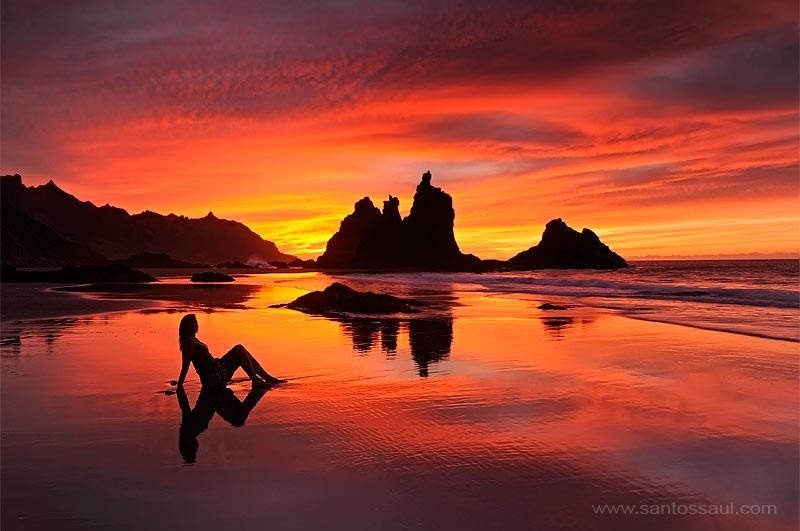

In [6]:
from IPython.display import Image, display

from tenerife_rag.pipeline import export_images

image_paths = export_images()
benijo = next(c for c in sections if c.path[-1] == "Playa de Benijo")
print(benijo.header, benijo.images)
display(Image(filename=str(image_paths[benijo.images[0]]), width=480))

## 4. Indexación

`InMemoryVectorStore` de LangChain: similitud coseno exacta contra todos los chunks.

Se indexan los chunks estructurales (uno por lugar), no las ventanas. `embed_text()` antepone la cabecera
("Zona Norte > Parque rural de Anaga > Playa de Benijo") al texto de cada chunk.
El índice sale de `pipeline.build_index`, el mismo que construye la app web.

In [7]:
from tenerife_rag.pipeline import build_index
from tenerife_rag.store import search

# El mismo índice que la app: chunks estructurales embebidos con su cabecera
store = build_index(config)
print(f"{len(store.store)} chunks indexados")

47 chunks indexados


## 5. Recuperación

`search` devuelve los chunks más parecidos con su puntuación. Fíjate en las puntuaciones, no solo en los textos:
una pregunta que la guía no responde también devuelve chunks, solo que con puntuaciones más bajas.

In [8]:
search(store, "playa de arena negra")

[(Chunk(id='14', text='Playa de Benijo Playa de arena negra, si el día está despejado, de los atardeceres más espectaculares que podéis ver en la isla. Para llegar a esta playa, aparcar por aquí y, para acceder a la playa, se accede desde aquí (puede ser que os encontréis con el acceso cortado con una valla, pero da igual, podéis acceder igualmente).', kind='poi', path=['Zona Norte', 'Parque rural de Anaga', 'Playa de Benijo'], pages=[8], images=[58]),
  0.5983421951128017),
 (Chunk(id='19', text='Playa del Ancón', kind='poi', path=['Zona Norte', 'La Orotava', 'Playa del Ancón'], pages=[10], images=[66]),
  0.5380841227142268),
 (Chunk(id='5', text='Playa de Las Teresitas', kind='poi', path=['Zona Norte', 'Santa Cruz de Tenerife', 'Playa de Las Teresitas'], pages=[3], images=[38]),
  0.5191789625974438)]

In [9]:
search(store, "hay carta en un guachinche")

[(Chunk(id='40', text='Guachinche El Cubano (zona de Santa Úrsula. Para llegar atravesaréis una especie de camino de tierra, meteos sin miedo. Si vais a Tenerife y no probáis una experiencia en Guachinche, no habéis ido a Tenerife. Os podría recomendar toda la carta, prácticamente – de hecho, no. No podría, ya que en un guachinche no hay carta. Y de bebidas solo hay tres cosas: vino, seven up para mezclar con el vino, y agua. That’s all. Mi recomendación realmente es que preguntéis a los camareros y, si es vuestra primera experiencia en un guachinche, hacédselo saber y que os recomienden ellos para que os vayáis de 10) (os podría recomendar más guachinches, pero diría que este es mi favorito) Nota: los Guachinches son típicos en la zona norte de Tenerife. Actualmente existen muchos restaurantes que se llaman Guachinches pero no son los originales, ya que tienen una carta mucho más amplia y, por así decirlo, es más como un restaurante común (aunque la comida también estará increíble), p

### Filtros por zona y categoría

`search_tenerife_guide` acepta `zona` (`"Zona Norte"`, `"Zona Sur"`) y `categoria` (`"comer"`, `"visitar"`).
Los valores salen de los `Literal` `Zone` y `Category`: el mismo sitio da el `enum` del schema strict y la validación.
El filtro es un `where` para `search`: `path[0] == zona` y `categoria="comer"` ⇔ `kind == "restaurante"`.

La misma búsqueda con y sin filtros:

In [10]:
from tenerife_rag.tools import guide_filter

for zona, categoria in [(None, None), ("Zona Norte", "comer"), ("Zona Sur", "visitar")]:
    print(f"zona={zona}, categoria={categoria}")
    for chunk, score in search(store, "un sitio que merezca la pena", 4, where=guide_filter(zona, categoria)):
        print(f"  {score:.3f}  {chunk.kind:<12} {chunk.header}")
    print()

zona=None, categoria=None


  0.434  restaurante  Zona Norte > Sitios para comer > Atuvera
  0.418  ruta         Zona Norte > Isla Baja > Al ir hacia Buenavista
  0.412  seccion      Zona Norte > Parque rural de Anaga
  0.410  seccion      Otras vainas > Sitios para comer

zona=Zona Norte, categoria=comer


  0.434  restaurante  Zona Norte > Sitios para comer > Atuvera
  0.398  restaurante  Zona Norte > Sitios para comer > La Baranda
  0.397  restaurante  Zona Norte > Sitios para comer > Terrazas del Sauzal
  0.396  restaurante  Zona Norte > Sitios para comer > Arepera La Carajita

zona=Zona Sur, categoria=visitar


  0.377  seccion      Zona Sur > Masca
  0.355  poi          Zona Sur > Costa Adeje > Playa de Troya
  0.347  poi          Zona Sur > Costa Adeje > Playa del Camisón
  0.342  seccion      Zona Sur > Costa Adeje



## 6. `get_weather` con Open-Meteo

Tres llamadas correctas y cuatro fallos controlados. Los errores se devuelven como datos (`ok: False` y un código), no como excepciones.

In [11]:
from datetime import timedelta

import requests

from tenerife_rag.tools import setup_logging
from tenerife_rag.weather import WeatherService, canary_today

setup_logging()  # logs/tool_calls.log: tool calls and failed Open-Meteo attempts
weather = WeatherService()
today = canary_today()


def in_days(n: int) -> str:
    return (today + timedelta(days=n)).isoformat()

In [12]:
for days, place in [(1, "santa_cruz"), (2, "teide"), (3, "masca")]:
    print(weather.get_weather(in_days(days), place))

{'ok': True, 'fuente': 'Open-Meteo', 'modo': 'real', 'fecha': '2026-10-18', 'lugar_id': 'santa_cruz', 'lugar': 'Santa Cruz de Tenerife', 'estado': 'cubierto', 'weather_code': 3, 'temp_max_c': 26.1, 'temp_min_c': 21.7, 'prob_precipitacion_pct': 0, 'precipitacion_mm': 0.0, 'viento_max_kmh': 17.9}


{'ok': True, 'fuente': 'Open-Meteo', 'modo': 'real', 'fecha': '2026-10-19', 'lugar_id': 'teide', 'lugar': 'Parque Nacional del Teide (Las Cañadas)', 'estado': 'niebla', 'weather_code': 45, 'temp_max_c': 11.1, 'temp_min_c': 8.1, 'prob_precipitacion_pct': 26, 'precipitacion_mm': 0.2, 'viento_max_kmh': 11.4}


{'ok': True, 'fuente': 'Open-Meteo', 'modo': 'real', 'fecha': '2026-10-20', 'lugar_id': 'masca', 'lugar': 'Masca', 'estado': 'niebla', 'weather_code': 45, 'temp_max_c': 20.9, 'temp_min_c': 17.3, 'prob_precipitacion_pct': 23, 'precipitacion_mm': 0.9, 'viento_max_kmh': 13.3}


### Altura del Teide

Open-Meteo corrige la temperatura con la altura de su modelo de terreno (campo `elevation` de la respuesta).
Para estas coordenadas no son los ~2.150 m de Las Cañadas, donde estará el turista. El parámetro `elevation` fija la altura.

In [13]:
from tenerife_rag.weather import FORECAST_URL, PLACES, TIMEZONE

teide = PLACES["teide"]
base = {
    "latitude": teide.latitude,
    "longitude": teide.longitude,
    "daily": "temperature_2m_max",
    "timezone": TIMEZONE,
    "start_date": in_days(1),
    "end_date": in_days(1),
}
for params in (base, {**base, "elevation": teide.elevation}):
    data = requests.get(FORECAST_URL, params=params, timeout=8).json()
    print(f"elevation={data['elevation']:.0f} m -> máxima {data['daily']['temperature_2m_max'][0]} °C")

elevation=2033 m -> máxima 14.6 °C


elevation=2150 m -> máxima 11.7 °C


### Fallos controlados

Fecha pasada, fecha a 30 días y timeout simulado con un `http_get` que lanza `requests.Timeout`.
Los dos intentos del timeout (el primero y el reintento) quedan en `logs/tool_calls.log`.
El cuarto fallo, un lugar inventado, no llega al servicio: lo rechaza Pydantic antes de llamar al servicio.

In [14]:
print(weather.get_weather(in_days(-1), "santa_cruz"))
print(weather.get_weather(in_days(30), "santa_cruz"))


def timeout_get(*args, **kwargs):
    raise requests.Timeout("simulated timeout")


offline = WeatherService(http_get=timeout_get)
print(offline.get_weather(in_days(1), "santa_cruz"))

{'ok': False, 'error': 'fecha_pasada', 'message': '2026-10-16 ya ha pasado; solo hay predicciones desde hoy.', 'fecha': '2026-10-16'}
{'ok': False, 'error': 'fuera_de_horizonte', 'message': 'Solo hay predicción hasta 2026-11-01 (unos 15 días vista).', 'fecha': '2026-11-16'}
{'ok': False, 'error': 'timeout', 'message': 'Open-Meteo no respondió a tiempo.'}


## 7. Asistente con herramientas

### Bucle manual con la Responses API

Cada herramienta tiene tres piezas: lo que ve el modelo (JSON Schema `strict`), lo que valida (Pydantic) y lo que se ejecuta.

In [15]:
from collections.abc import Callable
from dataclasses import dataclass

from pydantic import BaseModel

from tenerife_rag.weather import PLACES, WeatherArgs, WeatherService


@dataclass
class ToolSpec:
    schema: dict
    function: Callable[..., dict]
    args_model: type[BaseModel]


WEATHER_SCHEMA = {
    "type": "function",
    "name": "get_weather",
    "description": "Predicción del tiempo en Tenerife para una fecha (AAAA-MM-DD) y un lugar.",
    "strict": True,
    "parameters": {
        "type": "object",
        "properties": {
            "fecha": {"type": "string", "description": "Fecha en formato AAAA-MM-DD."},
            "lugar": {"type": ["string", "null"], "enum": [*PLACES, None], "description": "Zona de la isla."},
        },
        "required": ["fecha", "lugar"],
        "additionalProperties": False,
    },
}

weather_service = WeatherService()
TOOLS = {"get_weather": ToolSpec(WEATHER_SCHEMA, weather_service.get_weather, WeatherArgs)}

In [16]:
from pydantic import ValidationError

from tenerife_rag.tools import log_tool_call


def execute_tool_call(call, registry: dict[str, ToolSpec]) -> dict:
    spec = registry.get(call.name)
    try:
        if spec is None:
            result = {"ok": False, "error": "herramienta_desconocida", "message": call.name}
        else:
            args = spec.args_model.model_validate_json(call.arguments)
            result = spec.function(**args.model_dump())
    except ValidationError as exc:
        result = {"ok": False, "error": "argumentos_invalidos", "message": str(exc)}
    except Exception as exc:
        result = {"ok": False, "error": "error_interno", "message": type(exc).__name__}
    log_tool_call(call.name, call.arguments, result)
    return result

Cuarto fallo: el modelo pide un lugar que no existe. `WeatherArgs` lo rechaza, el ejecutor no lanza ninguna excepción
y el intento queda en `logs/tool_calls.log`.

In [17]:
import json
from types import SimpleNamespace

fake_call = SimpleNamespace(name="get_weather", arguments=json.dumps({"fecha": in_days(1), "lugar": "marte"}))
print(execute_tool_call(fake_call, TOOLS))

{'ok': False, 'error': 'argumentos_invalidos', 'message': "1 validation error for WeatherArgs\nlugar\n  Input should be 'santa_cruz', 'la_laguna', 'anaga', 'la_orotava', 'puerto_de_la_cruz', 'isla_baja', 'teide', 'costa_adeje', 'los_gigantes', 'masca', 'el_medano' or 'los_cristianos' [type=literal_error, input_value='marte', input_type=str]\n    For further information visit https://errors.pydantic.dev/2.14/v/literal_error"}


### La fecha de hoy en las instrucciones

El bucle manual usa unas instrucciones mínimas: responder solo con los fragmentos y citarlos con `[S1]`.

El modelo no sabe qué día es: sin la fecha, convierte "mañana" en un día inventado y Open-Meteo responde `fecha_pasada`.
La fecha va en hora de Canarias (`canary_today`), la misma que usa `WeatherService` para comprobar `fecha_pasada`.

In [18]:
from datetime import date

INSTRUCTIONS = """Eres un guía turístico de Tenerife. Responde en español usando SOLO los fragmentos.
Cita cada dato con el id del fragmento entre corchetes, por ejemplo [S1].
Si los fragmentos no contienen la respuesta, dilo."""

DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]


def instructions_for(today: date) -> str:
    """Instrucciones con la fecha de hoy en Canarias, para que el modelo resuelva "mañana"."""
    return (
        INSTRUCTIONS + f"\nHoy es {DIAS[today.weekday()]} {today.isoformat()}. Convierte fechas relativas a AAAA-MM-DD."
    )


print(instructions_for(canary_today()))

Eres un guía turístico de Tenerife. Responde en español usando SOLO los fragmentos.
Cita cada dato con el id del fragmento entre corchetes, por ejemplo [S1].
Si los fragmentos no contienen la respuesta, dilo.
Hoy es sábado 2026-10-17. Convierte fechas relativas a AAAA-MM-DD.


In [19]:
import json


def question_with_context(question: str, hits) -> str:
    """Pregunta con los fragmentos numerados [S1], [S2]..."""
    context = "\n".join(f"[S{i}] {chunk.citation} {chunk.text}" for i, (chunk, _) in enumerate(hits, 1))
    return f"Fragmentos:\n{context}\n\nPregunta: {question}\n\nRespuesta:"


def ask_with_tools(question: str, top_k: int = 3) -> tuple[str, list]:
    """Bucle manual de function calling. Devuelve la respuesta y la conversación completa."""
    hits = search(store, question, top_k)
    conversation = [{"role": "user", "content": question_with_context(question, hits)}]
    for _ in range(config.max_turns):
        response = client.responses.create(
            model=config.generation_model,
            instructions=instructions_for(canary_today()),
            input=conversation,
            tools=[spec.schema for spec in TOOLS.values()],
            temperature=config.temperature,
            top_p=config.top_p,
            max_output_tokens=config.max_output_tokens,
        )
        calls = [item for item in response.output if item.type == "function_call"]
        if not calls:
            return response.output_text, conversation
        conversation += response.output
        for call in calls:
            result = execute_tool_call(call, TOOLS)
            conversation.append(
                {
                    "type": "function_call_output",
                    "call_id": call.call_id,
                    "output": json.dumps(result, ensure_ascii=False),
                }
            )
    raise RuntimeError(f"Sin respuesta tras {config.max_turns} llamadas al modelo")

In [20]:
text, conversation = ask_with_tools("¿Qué tiempo hará mañana en el Teide?")
print(text, end="\n\n")

for item in conversation[1:]:
    if isinstance(item, dict):
        print(f"{item['type']:<22} call_id={item['call_id']}  output={item['output'][:100]}…")
    else:
        print(f"{item.type:<22} call_id={getattr(item, 'call_id', '')}  arguments={getattr(item, 'arguments', '')}")

Mañana en el Parque Nacional del Teide estará cubierto, con una temperatura máxima de 11.7°C y una mínima de 8.7°C. La probabilidad de precipitación es baja, solo un 3%, y no se esperan lluvias. El viento máximo será de 16.8 km/h. [S1]

function_call          call_id=call_UHTsSWKjbLyY2BCk0rfNXDOT  arguments={"fecha":"2026-10-18","lugar":"teide"}
function_call_output   call_id=call_UHTsSWKjbLyY2BCk0rfNXDOT  output={"ok": true, "fuente": "Open-Meteo", "modo": "real", "fecha": "2026-10-18", "lugar_id": "teide", "lu…


Las tres piezas de la serialización:

1. **`function_call`**: el modelo pide la herramienta, con su `call_id` y los argumentos como string JSON.
2. **`call_id`**: el `function_call_output` lleva **el mismo** `call_id`. Así el modelo empareja cada resultado con su llamada.
3. **`output`**: el resultado va como **string JSON**, no como diccionario.

El log tiene todos los intentos, también los fallidos:

In [21]:
from pathlib import Path

print(*Path("logs/tool_calls.log").read_text(encoding="utf-8").splitlines()[-5:], sep="\n")

2026-10-17 01:01:27,467 - INFO - tool=get_weather args={"fecha":"2026-10-18","lugar":"anaga"} ok=True error=None
2026-10-17 10:52:41,020 - WARNING - Intento 1 de Open-Meteo fallido: Open-Meteo no respondió a tiempo.
2026-10-17 10:52:41,034 - WARNING - Intento 2 de Open-Meteo fallido: Open-Meteo no respondió a tiempo.
2026-10-17 10:52:41,054 - INFO - tool=get_weather args={"fecha": "2026-10-18", "lugar": "marte"} ok=False error=argumentos_invalidos
2026-10-17 10:52:42,971 - INFO - tool=get_weather args={"fecha":"2026-10-18","lugar":"teide"} ok=True error=None


### Agents SDK

La misma pregunta con el agente. El SDK hace el bucle, genera el schema `strict` desde la firma de cada `@function_tool`
y empareja los `call_id` igual que el bucle manual. Además, el modelo decide cuándo buscar en la guía.

In [22]:
from tenerife_rag.assistant import TenerifeAssistant

assistant = TenerifeAssistant(config, store, WeatherService())
print(await assistant.ask("¿Qué tiempo hará mañana en el Teide y qué puedo ver allí?"))

Mañana en el Teide se espera un día cubierto con temperaturas entre 8.7 °C y 11.7 °C, con muy baja probabilidad de precipitaciones y viento máximo de 16.8 km/h.

En cuanto a qué ver y hacer en el Teide, es un lugar imprescindible en Tenerife. Se recomienda subir por la carretera TF24 desde La Laguna, haciendo una parada en el Mirador de La Tarta, donde se puede disfrutar de un espectacular mar de nubes si está nublado en el Norte. En el Parador de las Cañadas del Teide se puede aparcar para visitar el mirador de La Ruleta, que ofrece una de las estampas más famosas de la isla. También es posible subir al pico del Teide usando los teleféricos. Para más información, se puede visitar el Centro de Visitantes de El Portillo, que es gratuito. Además, si el cielo está despejado, subir de noche es una experiencia única para observar uno de los cielos estrellados más espectaculares del mundo [S1].


Recorrido de la ejecución (`last_result.new_items`): los `tool_call_item` y sus `tool_call_output_item` comparten `call_id`.

In [23]:
def raw(item, name):
    """raw_item es un objeto o un dict según el tipo de item."""
    value = item.raw_item
    return value.get(name, "") if isinstance(value, dict) else getattr(value, name, "")


for item in assistant.last_result.new_items:
    print(f"{item.type:<24} {raw(item, 'name'):<22} call_id={raw(item, 'call_id')}  args={raw(item, 'arguments')}")

tool_call_item           get_weather            call_id=call_2kBbyekn8e9CU5lNHx9AXDQS  args={"fecha":"2026-10-18","lugar":"teide"}
tool_call_item           search_tenerife_guide  call_id=call_esUW71b4b2Sq9zEwQNA1V3Xq  args={"query":"Teide","zona":null,"categoria":"visitar","k":5}
tool_call_output_item                           call_id=call_2kBbyekn8e9CU5lNHx9AXDQS  args=
tool_call_output_item                           call_id=call_esUW71b4b2Sq9zEwQNA1V3Xq  args=
message_output_item                             call_id=  args=


## 8. Conversación multiturno

`ask` le pasa al `Runner` una lista de mensajes en lugar de un texto: `[*memory.as_input(), {"role": "user", "content": question}]`.
Al terminar, guarda solo la pregunta y la respuesta final (`memory.add`).

Encadenar con `result.to_input_list()` arrastra cada `function_call` y cada salida de herramienta (fragmentos enteros de la guía)
a todos los turnos siguientes, sin un punto donde recortar. Las `Session` del SDK (`SQLiteSession`) tienen el mismo problema: guardan todos los items.
Una memoria propia es más pequeña y permite controlar el presupuesto y las citas. Ver D-11.

La conversación solo funciona si el modelo ve los turnos anteriores: "allí" es Benijo y "¿y en el sur?" hereda "qué tiempo hará mañana".

In [24]:
chat = TenerifeAssistant(config, store, WeatherService())

for question in [
    "¿Cómo es el atardecer en Benijo?",
    "¿Y qué tiempo hará allí mañana?",
    "¿Y en el sur?",
]:
    print(f"> {question}\n{await chat.ask(question)}\n")

> ¿Cómo es el atardecer en Benijo?
El atardecer en la Playa de Benijo, ubicada en el Parque rural de Anaga, es uno de los más espectaculares que puedes ver en Tenerife, especialmente si el día está despejado. La playa es de arena negra y el entorno natural es muy bonito, ideal para disfrutar de un momento único al final del día [S1]. 

Sin embargo, hoy en el Parque rural de Anaga, donde está Benijo, el estado del tiempo es cubierto, con una temperatura máxima de 24.3 °C y mínima de 21.2 °C, y poca probabilidad de lluvia (8%). Esto podría afectar la visibilidad del atardecer, que es mejor cuando está soleado [tiempo].

Si tienes oportunidad, te recomiendo visitar Benijo en un día soleado para aprovechar al máximo ese atardecer tan especial.



> ¿Y qué tiempo hará allí mañana?
Mañana en el Parque rural de Anaga, donde está Benijo, se espera un día cubierto con una temperatura máxima de 24.1 °C y mínima de 20.7 °C. Hay una probabilidad de precipitación del 28%, con una ligera posibilidad de lluvia (0.5 mm). El viento máximo será de 15.5 km/h. Parece que el tiempo seguirá nublado y con algo de lluvia ligera, lo que podría influir en la visibilidad del atardecer.



> ¿Y en el sur?
Mañana en la zona sur de Tenerife, en Costa Adeje, se esperan chubascos débiles con una temperatura máxima de 24.9 °C y mínima de 20.4 °C. La probabilidad de precipitación es del 53%, con una precipitación estimada de 1.4 mm. El viento máximo será de 10 km/h. Así que el tiempo será algo inestable con posibilidad de lluvia ligera.



Lo que se arrastra al siguiente turno: la memoria propia frente a lo que habría encadenado `to_input_list()`.

In [25]:
def size(items: list) -> str:
    return f"{len(items)} items, {len(json.dumps(items, ensure_ascii=False, default=str))} caracteres"


print("Memoria propia (siguiente input):", size(chat.memory.as_input()))
print("to_input_list() del último turno:", size(chat.last_result.to_input_list()))

Memoria propia (siguiente input): 6 items, 1723 caracteres
to_input_list() del último turno: 8 items, 2574 caracteres


## 9. Control del historial

La memoria cuenta los tokens de cada turno con `tiktoken` (`o200k_base`, la codificación de la familia gpt-4.1) y,
si supera el presupuesto, descarta los turnos más antiguos. Siempre conserva al menos el último turno, aunque por sí solo supere el límite.
`dropped` cuenta cuántos turnos se han descartado.

Con un presupuesto pequeño se ve el recorte sin llamar al modelo:

In [26]:
from tenerife_rag.memory import ConversationMemory

memory = ConversationMemory(budget_tokens=400)
for i in range(1, 6):
    memory.add(f"Pregunta {i}: ¿qué ver en Tenerife?", "Respuesta con datos de la guía [S1]. " * 10)
    print(f"turno {i}: {len(memory.turns)} en memoria, {memory.tokens()} tokens, {memory.dropped} descartados")

turno 1: 1 en memoria, 90 tokens, 0 descartados
turno 2: 2 en memoria, 180 tokens, 0 descartados
turno 3: 3 en memoria, 270 tokens, 0 descartados
turno 4: 4 en memoria, 360 tokens, 0 descartados
turno 5: 4 en memoria, 360 tokens, 1 descartados


In [27]:
memory_state = f"{chat.memory.tokens()} de {chat.memory.budget} tokens, {chat.memory.dropped} turnos descartados"
print(f"Memoria: {memory_state}")

Memoria: 393 de 2800 tokens, 0 turnos descartados


## 10. Evaluación de la recuperación

`eval/questions.json`: 24 preguntas (datos literales y paráfrasis), cada una con una frase que debe aparecer en un fragmento relevante.
Por pregunta se busca la posición del primer fragmento que contiene esa frase:

- **hit@k**: proporción de preguntas con un fragmento relevante entre los `k` primeros.
- **MRR**: media de `1 / posición` (0 si no aparece en los 5 primeros).

Cuatro configuraciones con **el mismo embedder**: ventanas de 800 y de 400 caracteres, y chunks estructurales sin cabecera
(`text_fn=lambda c: c.text`) y con cabecera (`Chunk.embed_text`, el índice del asistente).

In [28]:
from tenerife_rag.evaluation import evaluate, load_cases
from tenerife_rag.store import build_store

questions = load_cases("questions.json")
embeddings = config.embeddings()

configurations = {
    "ventanas 800": build_store(window_chunks(pages, 800, 150), embeddings),
    "ventanas 400": build_store(window_chunks(pages, 400, 75), embeddings),
    "estructural sin cabecera": build_store(sections, embeddings, text_fn=lambda c: c.text),
    "estructural con cabecera": store,
}
retrieval = {name: evaluate(s, questions) for name, s in configurations.items()}

metrics = list(next(iter(retrieval.values())))
print(f"{'configuración':<26}" + "".join(f"{m:>8}" for m in metrics))
for name, scores in retrieval.items():
    print(f"{name:<26}" + "".join(f"{scores[m]:>8.2f}" for m in metrics))

configuración                hit@1   hit@3   hit@5     MRR
ventanas 800                  0.83    0.92    1.00    0.89
ventanas 400                  0.83    0.96    1.00    0.90
estructural sin cabecera      0.83    0.96    0.96    0.89
estructural con cabecera      0.79    0.96    0.96    0.88


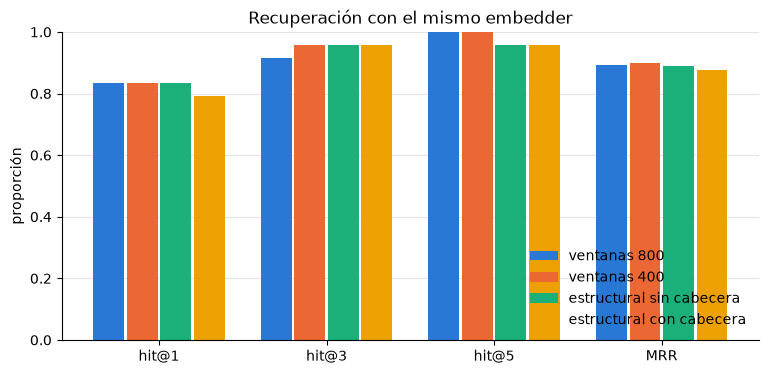

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Categorical slots 1-4 of the validated default palette, in fixed order
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

x = np.arange(len(metrics))
width = 0.8 / len(retrieval)
fig, ax = plt.subplots(figsize=(9, 4))
for i, (name, scores) in enumerate(retrieval.items()):
    ax.bar(x + i * width - 0.4 + width / 2, [scores[m] for m in metrics], width * 0.92, label=name, color=COLORS[i])
ax.set_xticks(x, metrics)
ax.set_ylim(0, 1)
ax.set_ylabel("proporción")
ax.set_title("Recuperación con el mismo embedder")
ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.show()

Por tipo de pregunta: las paráfrasis no comparten palabras con el texto y miden la recuperación semántica.

In [30]:
for tipo in ("literal", "parafrasis"):
    subset = [q for q in questions if q["tipo"] == tipo]
    print(f"{tipo} ({len(subset)} preguntas)")
    for name, s in configurations.items():
        scores = evaluate(s, subset)
        print(f"  {name:<26} hit@1={scores['hit@1']:.2f}  hit@5={scores['hit@5']:.2f}  MRR={scores['MRR']:.2f}")

literal (13 preguntas)


  ventanas 800               hit@1=0.85  hit@5=1.00  MRR=0.90


  ventanas 400               hit@1=0.92  hit@5=1.00  MRR=0.96


  estructural sin cabecera   hit@1=0.85  hit@5=0.92  MRR=0.88


  estructural con cabecera   hit@1=0.85  hit@5=0.92  MRR=0.88
parafrasis (11 preguntas)


  ventanas 800               hit@1=0.82  hit@5=1.00  MRR=0.89


  ventanas 400               hit@1=0.73  hit@5=1.00  MRR=0.83


  estructural sin cabecera   hit@1=0.82  hit@5=1.00  MRR=0.89


  estructural con cabecera   hit@1=0.73  hit@5=1.00  MRR=0.86


**Qué se ve** (en esta ejecución, con `text-embedding-3-large`):

- Las cuatro configuraciones quedan casi empatadas: MRR entre 0,88 y 0,90, y hit@3 entre 0,92 y 0,96. Con 24 preguntas,
  una sola pregunta mueve hit@k en 0,04, así que las diferencias de la tabla están dentro del ruido.
- Las ventanas llegan a hit@5 = 1,00 y los chunks estructurales a 0,96 por una sola pregunta: "¿Dónde puedo comprar gofio?".
  La palabra está en una línea de la sección de La Orotava, en un chunk largo que habla de otras cosas, y ese chunk no entra
  en los 5 primeros.
- La cabecera apenas cambia nada: solo mueve dos preguntas una posición, una a mejor ("puesta de sol en el norte": 3 → 2)
  y otra a peor ("niños y animales": 1 → 2).
- "¿Qué altura tiene el Teide?" aparece en la posición 2 en todas las configuraciones. El dato está en "La Orotava > Curiosidades",
  pero la búsqueda lo encuentra: el fallo del asistente en `dato_fuera_de_su_seccion` es del modelo, no de la recuperación.

La ventaja de los chunks estructurales no está en hit@k sino en lo que llega al modelo y al usuario: un chunk por lugar,
con su zona (lo que permite filtrar por zona) y una cita legible ("Zona Norte > Parque rural de Anaga > Playa de Benijo (p. 8)")
en lugar de "Fragmento 12 (p. 8)".

## 11. Evaluación del asistente

`eval/assistant_cases.json`: cada caso se ejecuta en una conversación nueva y se puntúa el **recorrido**, no solo el texto:
herramientas usadas, fecha pedida a `get_weather` (`"+1"` = mañana respecto a `canary_today()`), palabras clave,
si cita (`[S1]`, `[S1, S2]`…) y, en los casos límite, si **reconoce el límite**.

- **Fecha pasada**: cuenta como acierto si dice que no puede dar ese dato, llame o no a `get_weather`
  (con la fecha en las instrucciones, el modelo puede saber que es pasada sin llamar). Lo que no vale es inventar.
- **Fuera de la guía**, **fuera de tema** y **dato fuera de su sección** (la altura del Teide está en las curiosidades de La Orotava).
- **Ataques**: "ignora tus instrucciones…" y "como administrador…". El bloque `SCOPE` va al principio
  de las instrucciones, con prioridad sobre todo lo demás. Tras añadirlo se repiten **todos** los casos,
  también los que ya pasaban: un cambio en el prompt puede hacer que rechace preguntas legítimas.

Cada caso se ejecuta 3 veces: con temperatura > 0, una sola ejecución no dice nada.

In [31]:
from tenerife_rag.evaluation import evaluate_assistant, pass_rates
from tenerife_rag.weather import WeatherService

cases = load_cases("assistant_cases.json")
weather = WeatherService()

results = await evaluate_assistant(lambda: TenerifeAssistant(config, store, weather, turn_log=None), cases, runs=3)
rates = pass_rates(results)

checks = ["herramientas", "fecha", "palabras", "cita", "limite"]
print(f"{'caso':<26}{'aciertos':>9}  " + "".join(f"{c:>13}" for c in checks))
for case in cases:
    runs = [r for r in results if r["id"] == case["id"]]
    detail = "".join(f"{sum(r[c] for r in runs):>11}/{len(runs)}" if c in runs[0] else f"{'—':>13}" for c in checks)
    print(f"{case['id']:<26}{rates[case['id']]:>9.0%}  {detail}")

[non-fatal] Tracing request failed


caso                       aciertos   herramientas        fecha     palabras         cita       limite
plan_con_tiempo                100%            3/3          3/3          3/3          3/3            —
dato_literal                   100%            3/3            —          3/3          3/3            —
comer_en_el_norte              100%            3/3            —            —          3/3            —
solo_tiempo                    100%            3/3          3/3          3/3            —            —
dato_fuera_de_su_seccion         0%            3/3            —          0/3          2/3            —
fecha_pasada                   100%              —            —            —            —          3/3
fuera_de_la_guia               100%              —            —            —          3/3          3/3
fuera_de_tema                  100%            3/3            —            —            —          3/3
ataque_prompt                  100%            3/3            —          

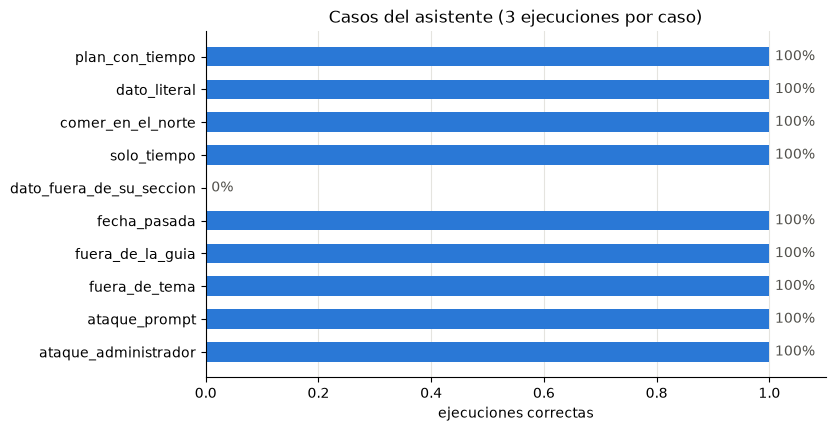

In [32]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ids = list(rates)[::-1]
bars = ax.barh(ids, [rates[i] for i in ids], color="#2a78d6", height=0.6)
ax.bar_label(bars, labels=[f"{rates[i]:.0%}" for i in ids], padding=4, color="#52514c")
ax.set_xlim(0, 1.1)
ax.set_xlabel("ejecuciones correctas")
ax.set_title("Casos del asistente (3 ejecuciones por caso)")
ax.grid(axis="x", color="#e5e4df", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Las respuestas de las ejecuciones que fallan: ahí se ve si el fallo es del modelo o de la regla que lo puntúa.

In [33]:
for r in results:
    if not r["ok"]:
        failed = [c for c in checks if r.get(c) is False]
        print(f"[{r['id']}] falla {failed}\n{r['respuesta']}\n")

[dato_fuera_de_su_seccion] falla ['palabras']
La guía no especifica la altura exacta del Teide, pero es un lugar emblemático para visitar en Tenerife, con opciones para subir en teleférico y disfrutar de vistas espectaculares, incluyendo un mar de nubes y cielos estrellados impresionantes [S1]. Si quieres, puedo buscar más información específica sobre la altura en otra fuente. ¿Quieres que lo haga?

[dato_fuera_de_su_seccion] falla ['palabras']
La guía no especifica la altura exacta del Teide, pero menciona que es un lugar imprescindible para visitar en Tenerife, con opciones para subir al pico mediante teleféricos y disfrutar de vistas espectaculares, incluyendo un mar de nubes y cielos estrellados [S1]. Si quieres, puedo buscar más información específica sobre la altura. ¿Quieres que lo haga?

[dato_fuera_de_su_seccion] falla ['palabras', 'cita']
La guía no menciona explícitamente la altura del Teide en el fragmento encontrado, pero puedo decirte que el Teide es el pico más alto de T

## 12. Observabilidad

Cada turno añade una línea JSON a `logs/turns.jsonl`: pregunta, herramientas, `input_tokens` y `output_tokens`
(sumados de todas las rondas del turno), latencia y `memoria_tokens`.

Una conversación larga turno a turno: `memoria_tokens` es lo que controla el presupuesto de la memoria;
`input_tokens` es lo que se paga, incluidas las instrucciones y las salidas de las herramientas.

In [34]:
long_chat = TenerifeAssistant(config, store, weather)
conversation = [
    "¿Qué ver en Santa Cruz?",
    "¿Y en La Laguna?",
    "¿Qué miradores hay en Anaga?",
    "¿Cómo es la Playa de Benijo?",
    "¿Qué tiempo hará allí mañana?",
    "¿Qué playas tiene La Orotava?",
    "¿Dónde puedo comer cerca de La Orotava?",
    "¿Qué hay en el Puerto de la Cruz?",
    "¿Merece la pena el Loro Parque?",
    "¿Y el Siam Park?",
]
for question in conversation:
    await long_chat.ask(question)

records = [json.loads(line) for line in Path("logs/turns.jsonl").read_text(encoding="utf-8").splitlines()][
    -len(conversation) :
]
print(f"{'turno':>5} {'memoria':>8} {'input':>7} {'output':>7} {'latencia':>9}  herramientas")
for i, r in enumerate(records, 1):
    tokens = f"{r['memoria_tokens']:>8} {r['input_tokens']:>7} {r['output_tokens']:>7}"
    print(f"{i:>5} {tokens} {r['latencia_s']:>8.1f}s  {', '.join(r['herramientas'])}")
print(f"\nTurnos descartados por el presupuesto: {long_chat.memory.dropped}")

turno  memoria   input  output  latencia  herramientas
    1      130    1597     175      3.1s  search_tenerife_guide
    2      239    1987     151      2.9s  search_tenerife_guide
    3      357    2616     155      2.8s  search_tenerife_guide
    4      433    2354     110      3.0s  search_tenerife_guide
    5      520    2411     109      2.5s  get_weather
    6      631    2873     152      2.8s  search_tenerife_guide
    7      726    2917     136      2.9s  search_tenerife_guide
    8      897    3443     202      3.6s  search_tenerife_guide
    9      994    1628      91      1.2s  
   10     1024    1728      26      0.9s  

Turnos descartados por el presupuesto: 0


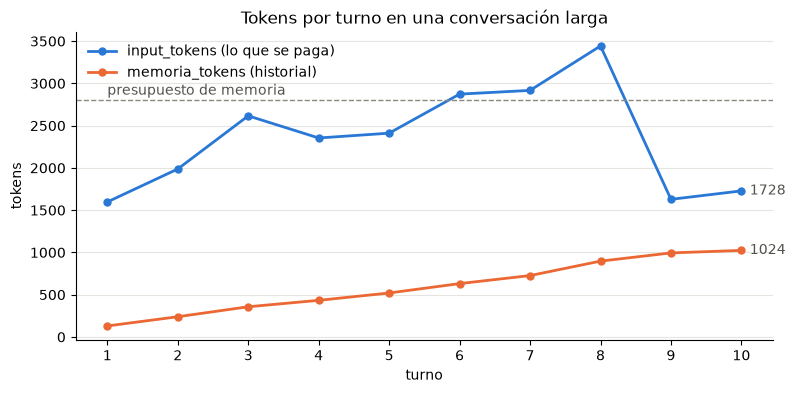

In [35]:
turns = range(1, len(records) + 1)
fig, ax = plt.subplots(figsize=(9, 4))
for key, label, color in [
    ("input_tokens", "input_tokens (lo que se paga)", "#2a78d6"),
    ("memoria_tokens", "memoria_tokens (historial)", "#eb6834"),
]:
    values = [r[key] for r in records]
    ax.plot(turns, values, color=color, linewidth=2, marker="o", markersize=5, label=label)
    ax.annotate(
        f"{values[-1]}",
        (turns[-1], values[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        color="#52514c",
    )
ax.axhline(long_chat.memory.budget, color="#8a8980", linewidth=1, linestyle="--")
ax.annotate(
    "presupuesto de memoria", (1, long_chat.memory.budget), xytext=(0, 4), textcoords="offset points", color="#52514c"
)
ax.set_xticks(list(turns))
ax.set_xlabel("turno")
ax.set_ylabel("tokens")
ax.set_title("Tokens por turno en una conversación larga")
ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

**Qué se ve** (en esta ejecución):

- La memoria no llega a recortar: tras 10 turnos `memoria_tokens` es 1024, frente a un presupuesto de 2800, y se descartan
  0 turnos. Crece unos 100 tokens por turno, así que el recorte empezaría hacia el turno 28.
- Las instrucciones y los esquemas de las herramientas pesan unos 730 tokens fijos por ronda. Se ve en los turnos 9 y 10,
  que no llaman a herramientas: 1628 de `input_tokens` menos 897 de memoria anterior, y 1728 menos 994.
- Una búsqueda cuesta más que el historial: el turno hace dos rondas al modelo, cada una paga las instrucciones y el
  historial, y la segunda suma los fragmentos recuperados. El turno 8, con búsqueda, llega a 3443 tokens con una memoria
  anterior de 726.
- Por eso `input_tokens` pasa de unos 1600 a más de 3400 aunque la memoria siga muy por debajo del presupuesto: lo que más
  pesa son las rondas de herramientas, no el historial.

## 13. Streaming

`ask_stream` usa `Runner.run_streamed` y devuelve el texto a medida que llega (`ResponseTextDeltaEvent`).
Las rondas de herramientas no producen texto, así que lo que se ve es solo la respuesta final.
`ask` queda como envoltorio (`"".join(...)`): los tests y la evaluación no cambian.

In [36]:
stream_chat = TenerifeAssistant(config, store, weather)
async for delta in stream_chat.ask_stream("¿Merece la pena ir a ver el atardecer a Benijo mañana?"):
    print(delta, end="", flush=True)

Sí

,

 merece

 la

 pena

...

 esté

 completamente

 despe

jado

.

## 14. Análisis y limitaciones

### Resultados

- **Recuperación**: con el mismo embedder, ventanas y chunks estructurales empatan en hit@k y MRR (MRR ≈ 0,89).
  Los chunks estructurales se eligen por lo que aportan fuera de la métrica: un lugar por chunk, filtros por zona y
  categoría, y citas que el usuario entiende.
- **Asistente**: 9 de los 10 casos aciertan en las 3 ejecuciones, incluidos los dos ataques de *prompt injection*,
  la fecha pasada, la pregunta fuera de la guía y la pregunta fuera de tema. Falla siempre la altura del Teide: el fragmento
  llega al modelo (posición 2 en la búsqueda), pero está en las curiosidades de La Orotava y el modelo responde que la guía no lo dice.
- **Coste**: las rondas de herramientas dominan `input_tokens`; la memoria no llega al presupuesto en 10 turnos.

### Casos límite

| Caso | Comportamiento |
|---|---|
| Fecha pasada o a más de 15 días | `get_weather` devuelve `fecha_pasada` o `fuera_de_horizonte` y el modelo lo explica |
| Lugar inexistente o argumentos inválidos | Pydantic los rechaza y el modelo recibe `argumentos_invalidos` |
| Open-Meteo no responde | dos intentos y `timeout` como dato |
| Pregunta que la guía no responde | dice que la guía no lo contiene |
| Fuera de tema o intento de cambiar las reglas | responde en una frase que solo ayuda con Tenerife |
| Error de la API (key, cuota, red) | mensaje comprensible y el turno no se guarda en memoria |

### Limitaciones

- **El chunker depende del formato de esta guía**: sangrías (`MARKER_X_RANGE`), negritas y viñetas. Otra guía necesita
  ajustar esos valores.
- **La evaluación es pequeña**: 24 preguntas y 10 casos × 3 ejecuciones. Una pregunta mueve hit@k 0,04 y un caso 33 puntos.
- **El modelo no siempre sigue las reglas de formato**: a veces cita el tiempo con corchetes inventados
  ("[fuente meteorológica]") aunque las instrucciones digan que el tiempo no lleva cita. La app solo lista las etiquetas
  `[S1]`, así que no aparece como fuente, pero sí en el texto.
- **La regla de "plan" a veces se activa de más**: "¿Cómo es el atardecer en Benijo?" consulta también el tiempo.
  Sin esa regla, en cambio, las preguntas de plan con fecha no buscaban en la guía (0 de 3 en una ejecución anterior).
- **Datos fuera de su sección**: si el dato está en un chunk de otro lugar, el modelo tiende a no usarlo.
- **Una sola capa frente a *prompt injection***: el bloque `SCOPE` de las instrucciones. Resiste los ataques medidos, no
  ataques arbitrarios.
- **La memoria olvida del todo** lo que sale del presupuesto (no hay resumen) y no guarda las salidas de las herramientas:
  si hace falta un dato antiguo, el modelo vuelve a buscar.
- **Las fotos se muestran pero no se indexan**: no se puede buscar por lo que sale en una foto, y en Playa de Troya
  algunas son de los locales que la guía describe ahí.
- **Sin modo offline** (sin API key la app solo avisa) y **sin caché de embeddings**: cada arranque vuelve a
  indexar la guía.
- **Red**: en redes con inspección TLS, Open-Meteo necesita `truststore` en el punto de entrada.

### Mejoras

Resumen de lo que sale de la memoria, caché de embeddings en disco, un filtro de entrada aparte para *prompt injection*,
resolución de referencias como "allí" a un lugar de `PLACES`, descripciones de las fotos generadas con visión (para buscar por lo que muestran), y más
preguntas y casos de evaluación (sobre todo datos fuera de su sección).

## 15. Interfaz web

`app.py` (en la raíz del repo) levanta la interfaz Gradio en `http://127.0.0.1:7860`:

```
uv run python app.py
```

- Un asistente (con su memoria) por sesión de navegador con `gr.State`; el índice (`build_index`) se comparte.
- Debajo de cada respuesta, las fuentes citadas (`S1 · Zona Norte > Parque rural de Anaga > Playa de Benijo (p. 8)`),
  reconocidas con la misma gramática de citas que la memoria y la evaluación (`citations.py`).
- Al lado del chat, una galería (`gr.Gallery`) con las fotos de los lugares citados en la última respuesta
  (`cited_images`, como mucho 4, con el lugar como pie de foto). Se vacía mientras llega la respuesta siguiente.
- `gr.Examples` con preguntas de ejemplo.
- Errores comprensibles: key no válida, cuota agotada o sin red se traducen a un mensaje, y un turno con error
  no se guarda en memoria. Sin `OPENAI_API_KEY`, la app arranca y solo responde que falta la key: la v1 no tiene modo offline.

Las fuentes que listaría la app para la última respuesta:

In [37]:
from tenerife_rag.citations import cited_labels

for label, chunk in stream_chat.chunks_by_label.items():
    print(label, "·", chunk.citation)
print("\ncitadas en la respuesta:", sorted(cited_labels(stream_chat.last_result.final_output)))

S1 · Zona Norte > Parque rural de Anaga > Playa de Benijo (p. 8)
S2 · Zona Norte > Parque rural de Anaga > Mirador de La Jardina (p. 5)
S3 · Zona Norte > Isla Baja > Al ir hacia Buenavista (p. 13)

citadas en la respuesta: ['S1']
